# Phase 8.1 - Mejora Two-Stage (Markov Mixture)

Esta versión busca mejorar la detección/predicción en cambios raros con una mezcla calibrada:
- `baseline Markov`
- `modelo de cambio` (detector + token de cambio)

El objetivo es mejorar métricas de cambio manteniendo rendimiento global razonable.

In [1]:
from pathlib import Path
import json
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path('.')
PHASE8 = ROOT / 'phases/phase08_two_stage_detector'

RUN_V81 = PHASE8 / 'run_phase8_1_two_stage_markov_mixture.py'
SUM_V8 = PHASE8 / 'output_phase8_two_stage_GBPUSD/GBPUSD_phase8_summary.json'
SUM_V81 = PHASE8 / 'output_phase8_1_two_stage_markov_mixture_GBPUSD/GBPUSD_phase8_1_summary.json'
FOLD_V81 = PHASE8 / 'output_phase8_1_two_stage_markov_mixture_GBPUSD/GBPUSD_phase8_1_fold_metrics.csv'


In [2]:
subprocess.run(['python', str(RUN_V81)], check=True)
print('Ejecutado:', RUN_V81)

Saved summary: ./phases/phase08_two_stage_detector/output_phase8_1_two_stage_markov_mixture_GBPUSD/GBPUSD_phase8_1_summary.json
Mean metrics: {'baseline_top1_all': 0.8001116010670151, 'baseline_top3_all': 0.8491071914638795, 'baseline_top5_all': 0.8576269802384452, 'baseline_top1_change': 0.0, 'baseline_top3_change': 0.4415898111550285, 'baseline_top5_change': 0.5135046113306984, 'baseline_detector_f1': 0.1920410273022742, 'model_top1_all': 0.8001116010670151, 'model_top3_all': 0.8384370406663401, 'model_top5_all': 0.8725025858783821, 'model_top1_change': 0.0, 'model_top3_change': 0.35584101888449715, 'model_top5_change': 0.6062801932367149, 'model_detector_precision': 0.1691919191919192, 'model_detector_recall': 0.3841677646025472, 'model_detector_f1': 0.22869365817403994, 'model_detector_roc_auc': 0.6045725023617656, 'model_detector_pr_auc': 0.21299424887250673}


Ejecutado: ./phases/phase08_two_stage_detector/run_phase8_1_two_stage_markov_mixture.py


In [3]:
s8 = json.loads(SUM_V8.read_text())
s81 = json.loads(SUM_V81.read_text())
fold81 = pd.read_csv(FOLD_V81)

print('phase8 model_tag:', s8['model_tag'])
print('phase8.1 model_tag:', s81['model_tag'])
print('n_vocab:', s81['n_vocab'], '| change_ratio_total:', round(s81['change_ratio_total'], 4))

phase8 model_tag: phase8_two_stage_change_detector_plus_next_token
phase8.1 model_tag: phase8_1_two_stage_markov_mixture
n_vocab: 16 | change_ratio_total: 0.0907


In [4]:
metrics = [
    'model_top1_all',
    'model_top3_all',
    'model_top5_all',
    'model_top1_change',
    'model_top3_change',
    'model_top5_change',
    'model_detector_f1',
    'model_detector_roc_auc',
    'model_detector_pr_auc',
]

rows = []
for m in metrics:
    rows.append({
        'metric': m,
        'phase8': float(s8['mean_metrics'].get(m, np.nan)),
        'phase8_1': float(s81['mean_metrics'].get(m, np.nan)),
        'delta_v81_minus_v8': float(s81['mean_metrics'].get(m, np.nan) - s8['mean_metrics'].get(m, np.nan)),
    })

cmp = pd.DataFrame(rows)
cmp.round(4)

,metric,phase8,phase8_1,delta_v81_minus_v8
0,model_top1_all,0.8787,0.8001,-0.0786
1,model_top3_all,0.9191,0.8384,-0.0807
2,model_top5_all,0.9532,0.8725,-0.0807
3,model_top1_change,0.0000,0.0000,0.0000
4,model_top3_change,0.3065,0.3558,0.0493
5,model_top5_change,0.5570,0.6063,0.0493
6,model_detector_f1,0.2531,0.2287,-0.0244
7,model_detector_roc_auc,0.6221,0.6046,-0.0175
8,model_detector_pr_auc,0.2253,0.2130,-0.0123


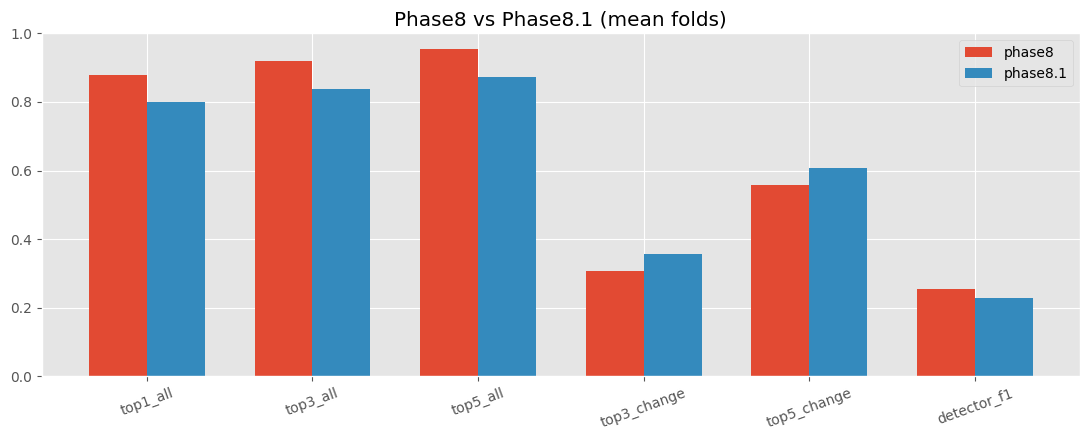

In [5]:
focus = cmp[cmp['metric'].isin(['model_top1_all','model_top3_all','model_top5_all','model_top3_change','model_top5_change','model_detector_f1'])].copy()
focus['metric'] = focus['metric'].str.replace('model_', '', regex=False)

plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(focus))
w = 0.35
ax.bar(x - w/2, focus['phase8'], width=w, label='phase8')
ax.bar(x + w/2, focus['phase8_1'], width=w, label='phase8.1')
ax.set_xticks(x)
ax.set_xticklabels(focus['metric'], rotation=20)
ax.set_ylim(0, 1)
ax.set_title('Phase8 vs Phase8.1 (mean folds)')
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
fold81.round(4)

,fold_id,n_train,n_val,n_test,n_train_change,n_val_change,n_test_change,detector_threshold,mix_thr,mix_temp,...,model_top3_change,model_top5_change,model_detector_precision,model_detector_recall,model_detector_f1,model_detector_roc_auc,model_detector_pr_auc,baseline_detector_precision,baseline_detector_recall,baseline_detector_f1
0,1,861,156,157,73,10,22,0.40,0.55,0.15,...,0.1364,0.5000,0.2167,0.5909,0.3171,0.6372,0.3027,0.1000,0.2727,0.1463
1,2,1017,157,157,83,22,12,0.55,0.70,0.05,...,0.5833,0.6667,0.0909,0.0833,0.0870,0.5322,0.0956,0.0764,1.0000,0.1420
2,3,1174,157,156,105,12,23,0.55,0.70,0.05,...,0.3478,0.6522,0.2000,0.4783,0.2821,0.6443,0.2406,0.1724,0.8696,0.2878


## Lectura recomendada

- Si el objetivo principal es estabilidad global, prioriza `top1/top3/top5_all`.
- Si el objetivo principal es capturar cambios raros, prioriza `top3/top5_change` y `detector_f1`.
- Usa la tabla por fold para confirmar consistencia temporal antes de mover a producción.